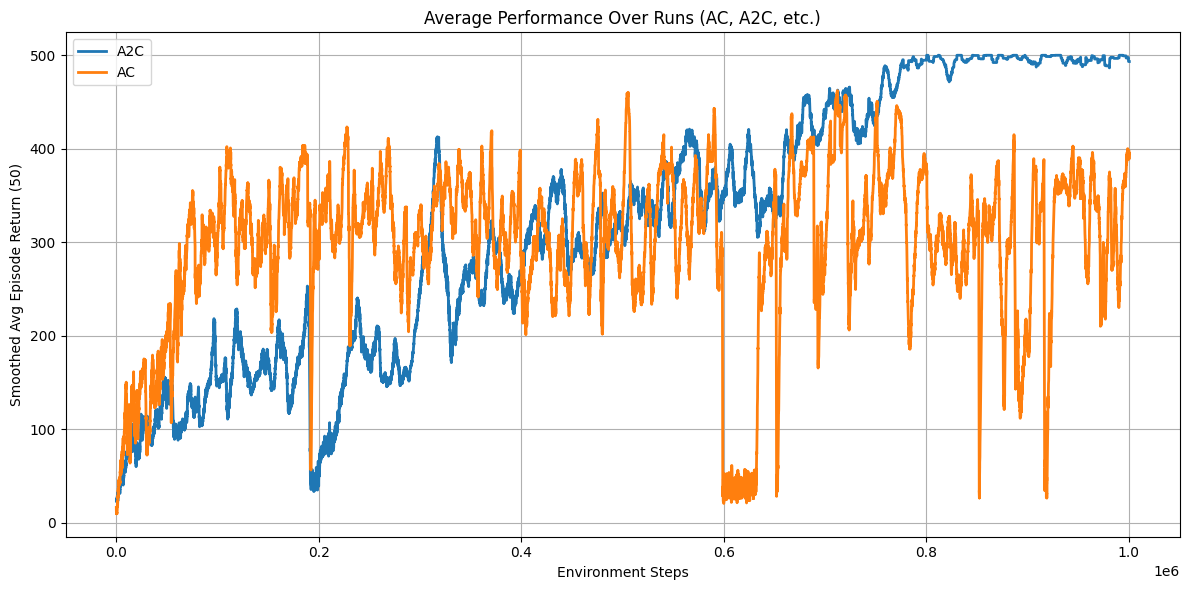

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size=50):
    return np.convolve(data, np.ones(window_size) / window_size, mode="valid")

df = pd.read_csv("ac_a2c_results_1e6.csv")

required_columns = {"Method", "Run", "EnvStep", "EpisodeReturn"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"CSV must contain columns: {required_columns}")

method_curves = {}

for method_name, method_df in df.groupby("Method"):
    grouped = method_df.groupby("EnvStep")["EpisodeReturn"].apply(list)

    avg_steps = []
    avg_returns = []
    for step, returns in grouped.items():
        avg_steps.append(step)
        avg_returns.append(np.mean(returns))

    avg_steps, avg_returns = zip(*sorted(zip(avg_steps, avg_returns)))

    smoothed = moving_average(avg_returns, window_size=50)
    aligned_steps = avg_steps[len(avg_steps) - len(smoothed):]
    method_curves[method_name] = (aligned_steps, smoothed)

plt.figure(figsize=(12, 6))

for method, (steps, returns) in method_curves.items():
    plt.plot(steps, returns, label=method, linewidth=2)

plt.xlabel("Environment Steps")
plt.ylabel("Smoothed Avg Episode Return (50)")
plt.title("Average Performance Over Runs (AC, A2C, etc.)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()